In [1]:
from google.colab import files
uploaded = files.upload()
archive_path = next(iter(uploaded.keys()))
print("Uploaded:", archive_path)

Saving pbcseg_final_v1.tar to pbcseg_final_v1.tar
Uploaded: pbcseg_final_v1.tar


## 2. Extract and inspect the dataset

In [2]:
import os, tarfile, glob, collections, re
from PIL import Image
import pandas as pd
import numpy as np

EXTRACT_DIR = "/content/wbc_data"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with tarfile.open(archive_path, "r:*") as tar:
    root = os.path.abspath(EXTRACT_DIR)
    for member in tar.getmembers():
        target = os.path.abspath(os.path.join(EXTRACT_DIR, member.name))
        if not (target == root or target.startswith(root + os.sep)):
            raise ValueError(f"Unsafe archive path: {member.name}")
    tar.extractall(EXTRACT_DIR)

jpg_paths = sorted(glob.glob(os.path.join(EXTRACT_DIR, "**", "*.jpg"), recursive=True))
mask_paths = glob.glob(os.path.join(EXTRACT_DIR, "**", "*_mask.png"), recursive=True)
print("JPG images:", len(jpg_paths))
print("PNG masks:", len(mask_paths))
def get_label(path):
    name = os.path.basename(path).upper()
    prefix = name.split("_")[0]
    mapping = {
        "BA": "basophil",
        "EO": "eosinophil",
        "LY": "lymphocyte",
        "MO": "monocyte",
        "BNE": "neutrophil",
        "SNE": "neutrophil",
        "NEUTROPHIL": "neutrophil",
    }
    return mapping.get(prefix)

rows = []
unmapped = []
for p in jpg_paths:
    label = get_label(p)
    if label is None:
        unmapped.append(os.path.basename(p))
    else:
        rows.append({"path": p, "filename": os.path.basename(p), "label": label})

df = pd.DataFrame(rows)
print("Unmapped images:", len(unmapped), unmapped[:10])
print("\nClass counts:")
display(df["label"].value_counts().rename_axis("class").to_frame("images"))
bad_images = []
dimensions = collections.Counter()
for p in jpg_paths:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            dimensions[(im.size, im.mode)] += 1
    except Exception:
        bad_images.append(p)
print("\nDimensions/modes:", dimensions.most_common(10))
print("Corrupt JPGs:", len(bad_images))

/tmp/ipykernel_2888/1323326886.py:15: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(EXTRACT_DIR)


JPG images: 10298
PNG masks: 10298
Unmapped images: 0 []

Class counts:


,images
class,
neutrophil,3329
eosinophil,3117
monocyte,1420
basophil,1218
lymphocyte,1214



Dimensions/modes: [(((360, 360), 'RGB'), 10298)]
Corrupt JPGs: 0


## 3. Split data (stratified) and create TensorFlow datasets

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(SEED)

train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"]
)

class_names = ["basophil", "eosinophil", "lymphocyte", "monocyte", "neutrophil"]
class_to_id = {name: i for i, name in enumerate(class_names)}

for part in (train_df, val_df, test_df):
    part["label_id"] = part["label"].map(class_to_id).astype("int32")

print("Train:", len(train_df), "Validation:", len(val_df), "Test:", len(test_df))
print("\nTraining distribution:")
display(train_df["label"].value_counts().reindex(class_names).to_frame("images"))

def decode_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

def make_ds(part, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        part["path"].astype(str).values,
        part["label_id"].values
    ))
    if training:
        ds = ds.shuffle(min(len(part), 4096), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

classes = np.array(sorted(train_df["label_id"].unique()))
weights = compute_class_weight(class_weight="balanced", classes=classes,
                               y=train_df["label_id"].values)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", class_weights)

Train: 7208 Validation: 1545 Test: 1545

Training distribution:


,images
label,
basophil,852
eosinophil,2182
lymphocyte,850
monocyte,994
neutrophil,2330


Class weights: {0: 1.692018779342723, 1: 0.6606782768102658, 2: 1.696, 3: 1.450301810865191, 4: 0.6187124463519313}


## 4. Train model: EfficientNetB0

In [4]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.08),
], name="light_augmentation")

backbone = EfficientNetB0(
    include_top=False, weights="imagenet",
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)
backbone.trainable = False

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = augmentation(inputs)
x = backbone(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_wbc_efficientnetb0.keras",
        monitor="val_loss", save_best_only=True
    )
]

history1 = model.fit(
    train_ds, validation_data=val_ds, epochs=8,
    class_weight=class_weights, callbacks=callbacks
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ light_augmentation (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,976 (15.47 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/8
226/226 ━━━━━━━━━━━━━━━━━━━━ 46s 129ms/step - accuracy: 0.6584 - loss: 0.9537 - val_accuracy: 0.8117 - val_loss: 0.6405 - learning_rate: 0.0010
Epoch 2/8
226/226 ━━━━━━━━━━━━━━━━━━━━ 21s 91ms/step - accuracy: 0.8310 - loss: 0.5625 - val_accuracy: 0.8816 - val_loss: 0.4361 - learning_rate: 0.0010
Epoch 3/8
226/226 ━━━━━━━━━━━━━━━━━━━━ 23s 101ms/step - accuracy: 0.8602 - loss: 0.4568 - val_accuracy: 0.9133 - val_loss: 0.3436 - learning_rate: 0.0010
Epoch 4/8
226/226 ━━━━━━━━━━━━━━━━━━━━ 22s 97ms/step - accuracy: 0.8769 - loss: 0.3943 - val_accuracy: 0.9230 - val_loss: 0.3015 - learning_rate: 0.0010
Epoch 5/8
226/226 ━━━━━━━━━━━━━━━━━━━━ 21s 95ms/step - accuracy: 0.8832 - loss: 0.3628 - val_accuracy: 0.9282 - val_loss: 0.2803 - learning_rate: 0.0010
Epoch 6/8
226/226 ━━━━━━━━━━━━━━━━━━━━ 21s 94ms/step - accuracy: 0.8998 - loss: 0.3332 - val_accuracy: 0.9307 - val_loss: 0.2505 - learning_rate: 0.0010
Epoch 7/8
226/226 ━━━━━━━━━━━━━━━━━━━━ 21s 94ms/step - accuracy: 0.8968 - loss: 

## 5. Optional fine-tuning


In [5]:
backbone.trainable = True
for layer in backbone.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
history2 = model.fit(
    train_ds, validation_data=val_ds, epochs=3,
    class_weight=class_weights, callbacks=callbacks
)

Epoch 1/3
226/226 ━━━━━━━━━━━━━━━━━━━━ 42s 128ms/step - accuracy: 0.8282 - loss: 0.4720 - val_accuracy: 0.9405 - val_loss: 0.2070 - learning_rate: 1.0000e-05
Epoch 2/3
226/226 ━━━━━━━━━━━━━━━━━━━━ 25s 112ms/step - accuracy: 0.8855 - loss: 0.3322 - val_accuracy: 0.9411 - val_loss: 0.1755 - learning_rate: 1.0000e-05
Epoch 3/3
226/226 ━━━━━━━━━━━━━━━━━━━━ 27s 118ms/step - accuracy: 0.9102 - loss: 0.2695 - val_accuracy: 0.9456 - val_loss: 0.1687 - learning_rate: 1.0000e-05


## 6. Final test results and analysis

49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step - accuracy: 0.9437 - loss: 0.1743
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 111ms/step
TEST accuracy: 0.9437
TEST loss: 0.1743

Classification report:
              precision    recall  f1-score   support

    basophil     0.8702    0.9891    0.9258       183
  eosinophil     0.9930    0.9038    0.9463       468
  lymphocyte     0.9714    0.9341    0.9524       182
    monocyte     0.8445    0.9437    0.8914       213
  neutrophil     0.9699    0.9679    0.9689       499

    accuracy                         0.9437      1545
   macro avg     0.9298    0.9477    0.9370      1545
weighted avg     0.9480    0.9437    0.9443      1545



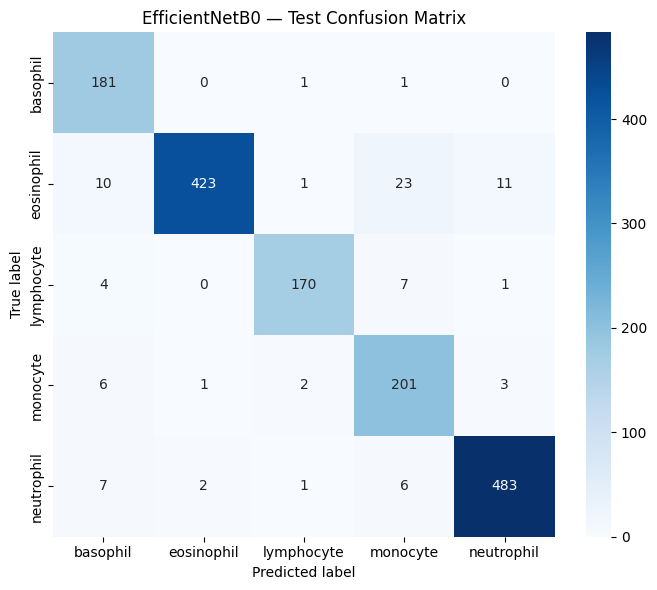

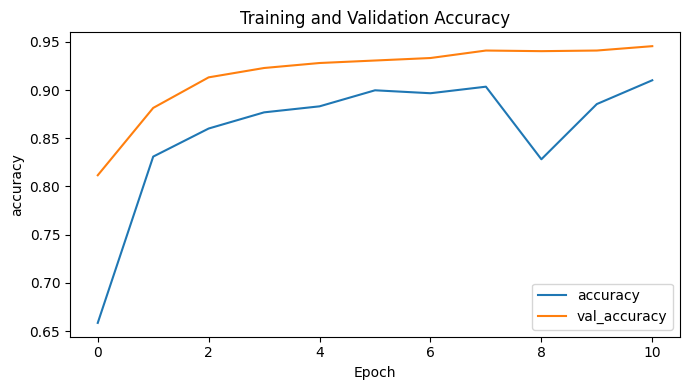

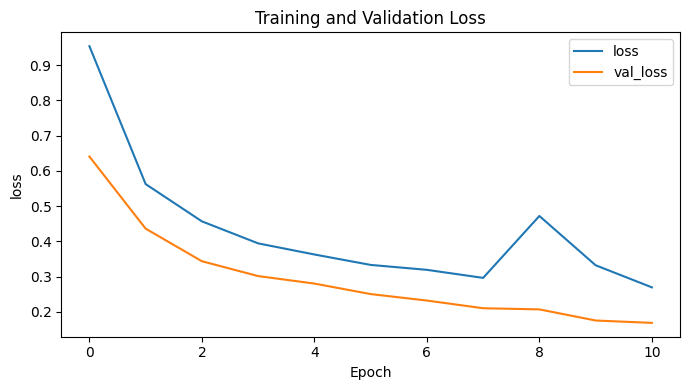

Saved model, report, confusion matrix, and plots in /content/


In [6]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
best_path = "/content/best_wbc_efficientnetb0.keras"
if os.path.exists(best_path):
    model = tf.keras.models.load_model(best_path)

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
probs = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probs, axis=1)

print(f"TEST accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"TEST loss: {test_loss:.4f}")
print("\nClassification report:")
report_text = classification_report(
    y_true, y_pred, labels=list(range(len(class_names))),
    target_names=class_names, digits=4, zero_division=0
)
print(report_text)

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("EfficientNetB0 — Test Confusion Matrix")
plt.tight_layout()
plt.savefig("/content/confusion_matrix.png", dpi=200)
plt.show()
def plot_histories(histories, metric, title, filename):
    vals, vvals = [], []
    for h in histories:
        vals.extend(h.history.get(metric, []))
        vvals.extend(h.history.get("val_" + metric, []))
    plt.figure(figsize=(7, 4))
    plt.plot(vals, label=metric)
    plt.plot(vvals, label="val_" + metric)
    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=200)
    plt.show()

plot_histories([history1, history2], "accuracy", "Training and Validation Accuracy", "/content/accuracy_curve.png")
plot_histories([history1, history2], "loss", "Training and Validation Loss", "/content/loss_curve.png")
model.save("/content/final_wbc_efficientnetb0.keras")
with open("/content/classification_report.txt", "w") as f:
    f.write(report_text)
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv("/content/confusion_matrix.csv")
print("Saved model, report, confusion matrix, and plots in /content/")

## 7. Download results

In [7]:
from google.colab import files
for path in [
    "/content/final_wbc_efficientnetb0.keras",
    "/content/classification_report.txt",
    "/content/confusion_matrix.csv",
    "/content/confusion_matrix.png",
    "/content/accuracy_curve.png",
    "/content/loss_curve.png",
]:
    if os.path.exists(path):
        files.download(path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>